In [2]:
#Downloading Libraries
!pip install matplotlib seaborn

In [3]:
#Importing Libraries
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 

In [4]:
#Importing Dataset
df=pd.read_csv('customer_churn_dataset.csv')
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.50,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.90,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.60,Yes


In [5]:
df.shape

(7043, 21)

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [7]:
#Checking NULL's
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [8]:
#Replacing NULL's with 0
df['TotalCharges']=df['TotalCharges'].replace(np.nan, 0)

In [9]:
#Adding a column of Total Services used by the customer
df['TotalServices'] = (
    (df['StreamingTV'] == 'Yes').astype(int) +
    (df['StreamingMovies'] == 'Yes').astype(int) +
    df['InternetService'].isin(['DSL', 'Fiber optic']).astype(int) +
    (df['PhoneService'] == 'Yes').astype(int) +
    (df['MultipleLines'] == 'Yes').astype(int) +
    (df['OnlineSecurity'] == 'Yes').astype(int) +
    (df['TechSupport'] == 'Yes').astype(int) +
    (df['DeviceProtection'] == 'Yes').astype(int) +
    (df['OnlineBackup'] == 'Yes').astype(int)
)

In [10]:
#Allocating Risk Categorization based on Tenurity, TotalServices and Contract
def assign_risk_profile(row):
    contract = row['Contract']
    tenure = row['tenure']
    services = row['TotalServices']
    
    if contract == 'Month-to-month' and (tenure <= 10 or services < 3):
        return 'High Risk'
    
    elif contract in ['One year', 'Two year'] and tenure > 12 and services > 3:
        return 'Low Risk'
    
    elif contract in ['Month-to-month', 'One year'] and tenure > 10 and services > 2:
        return 'Medium Risk'
    
    else:
        return 'Medium Risk'

In [11]:

df['RiskProfile'] = df.apply(assign_risk_profile, axis=1)


In [12]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk


In [13]:
#Summarizing the dataset
df.describe()

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,TotalServices
count,7043.000000,7043.000000,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692,2279.734304,4.146244
std,0.368612,24.559481,30.090047,2266.794470,2.312720
min,0.000000,0.000000,18.250000,0.000000,1.000000
25%,0.000000,9.000000,35.500000,398.550000,2.000000
50%,0.000000,29.000000,70.350000,1394.550000,4.000000
75%,0.000000,55.000000,89.850000,3786.600000,6.000000
max,1.000000,72.000000,118.750000,8684.800000,9.000000


In [14]:
df.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,...,7043,7043,7043,7043,7043,7043.000000,7043.000000,7043,7043.000000,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,...,3,3,3,2,4,NaN,NaN,2,NaN,3
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,NaN,NaN,No,NaN,Medium Risk
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,...,2810,2785,3875,4171,2365,NaN,NaN,5174,NaN,2913
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,64.761692,2279.734304,NaN,4.146244,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,30.090047,2266.794470,NaN,2.312720,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,18.250000,0.000000,NaN,1.000000,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,35.500000,398.550000,NaN,2.000000,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,70.350000,1394.550000,NaN,4.000000,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,89.850000,3786.600000,NaN,6.000000,NaN


In [15]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk


In [16]:
#Handling senior citizens column
def conv(value):
    if value==1:
        return 'Yes'
    else:
        return 'No'
df['SeniorCitizen']=df['SeniorCitizen'].apply(conv)

In [17]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk


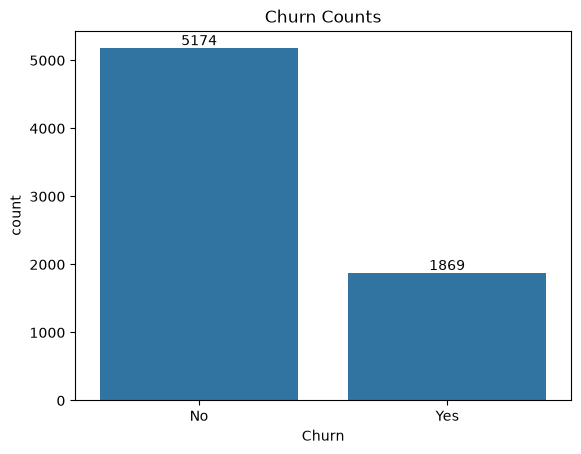

In [18]:
#Showcasing Churn counts via Bar Chart
ax=sns.countplot(x='Churn',data=df)

ax.bar_label(ax.containers[0])
plt.title("Churn Counts")
plt.show()

Total 1869 Customers Churned

In [19]:
gb=df.groupby('Churn').agg({'Churn':"count"})
gb

,Churn
Churn,
No,5174
Yes,1869


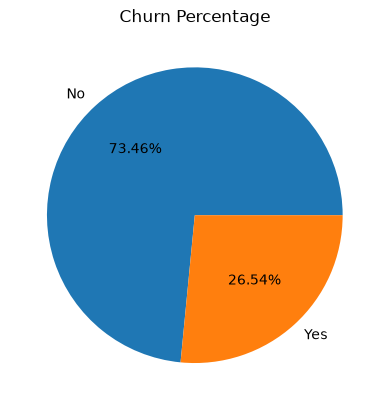

In [20]:
#Showcasing Churn% via Pie Chart
gb=df.groupby('Churn').agg({'Churn':"count"})
plt.pie(gb['Churn'],labels=gb.index,autopct="%1.2f%%")
plt.title("Churn Percentage")    
plt.show()

Churn Percentage is at 26.54%

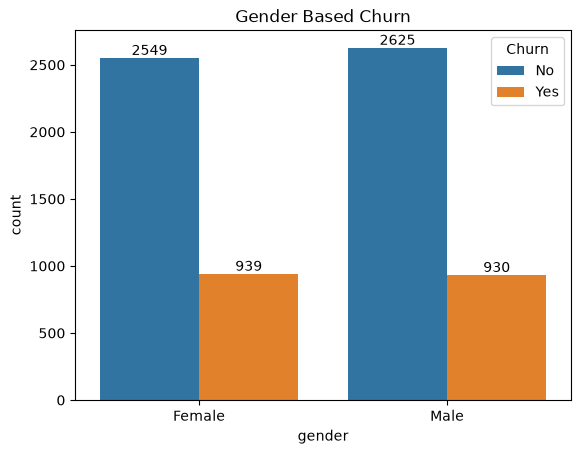

In [21]:
#Showcasing gender based churned users via Bar Chart
ax=sns.countplot(x='gender',data=df,hue='Churn')
for bars in ax.containers:
    ax.bar_label(bars)
    
plt.title("Gender Based Churn")
plt.show()

Higher Female Churned Users

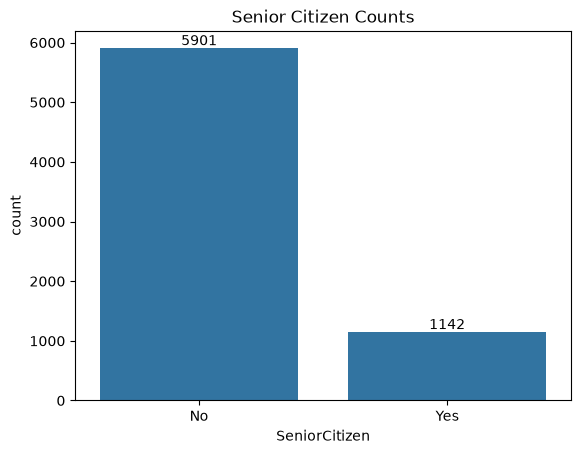

In [22]:
#Showcasing Senior Citizen counts via Bar Chart
ax=sns.countplot(x='SeniorCitizen',data=df)

ax.bar_label(ax.containers[0])
plt.title("Senior Citizen Counts")
plt.show()

Most users are not Senior Citizen

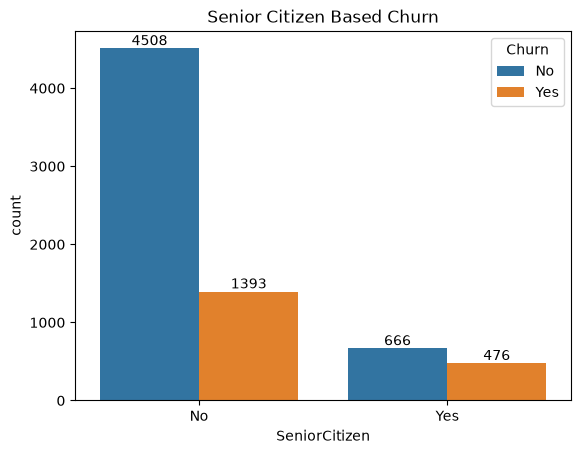

In [23]:
#Showcasing Senior Citizen based churned users via Bar Chart
ax=sns.countplot(x='SeniorCitizen',data=df,hue='Churn')
for bars in ax.containers:
    ax.bar_label(bars)
    
plt.title("Senior Citizen Based Churn")
plt.show()

Based on Senior Citizen counts, churned users rate are mainly Senior Citzen since the count is less. 

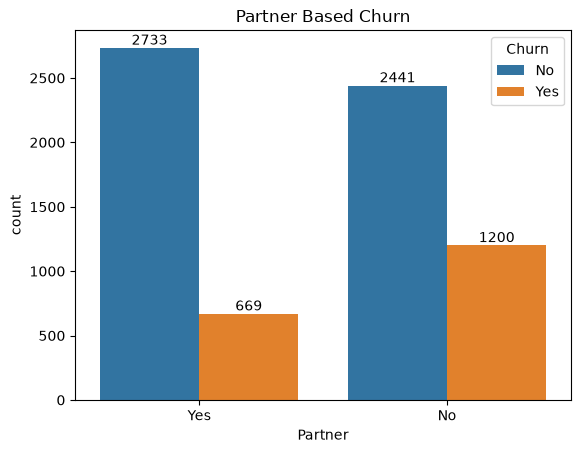

In [24]:
#Showcasing Partner based churned users via Bar Chart
ax=sns.countplot(x='Partner',data=df,hue='Churn')
for bars in ax.containers:
    ax.bar_label(bars)
    
plt.title("Partner Based Churn")
plt.show()

In [25]:
#Count of Churned Users based on Tenure
gb_tenure = df.groupby(['tenure', 'Churn']).agg({'Churn': 'count'})
gb_tenure

Churn
tenure Churn       
0      No        11
1      No       233
       Yes      380
2      No       115
       Yes      123
...             ...
70     Yes       11
71     No       164
       Yes        6
72     No       356
       Yes        6

[145 rows x 1 columns]

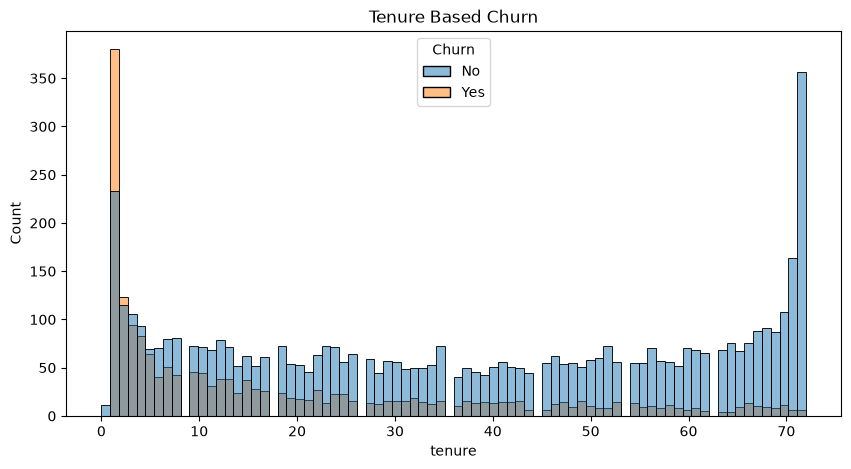

In [26]:
#Showcasing Tenure based churned users via Histplot
fig=plt.figure(figsize=(10,5))
sns.histplot(x='tenure',data=df,hue='Churn',bins=80)
plt.title("Tenure Based Churn")
plt.show()

Users with 1-5 Tenurity are mainly churned

In [27]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk


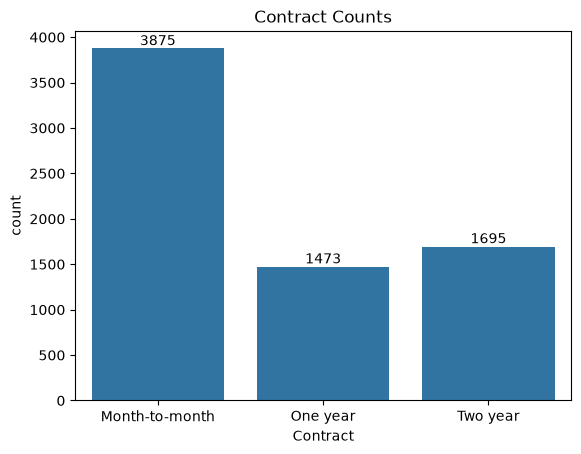

In [28]:
#Showcasing Contract counts via Bar Chart
ax=sns.countplot(x='Contract',data=df)

ax.bar_label(ax.containers[0])
plt.title("Contract Counts")
plt.show()

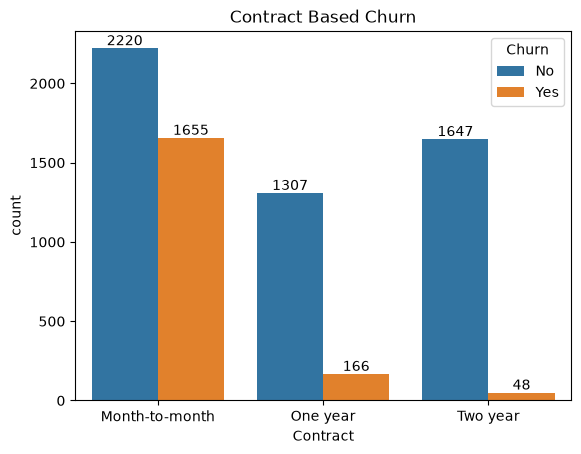

In [29]:
#Showcasing Contract based churned users via Bar Chart
ax=sns.countplot(x='Contract',data=df,hue='Churn')
for bars in ax.containers:
    ax.bar_label(bars)
    
plt.title("Contract Based Churn")
plt.show()

Month to Month contract's are mainly getting churned

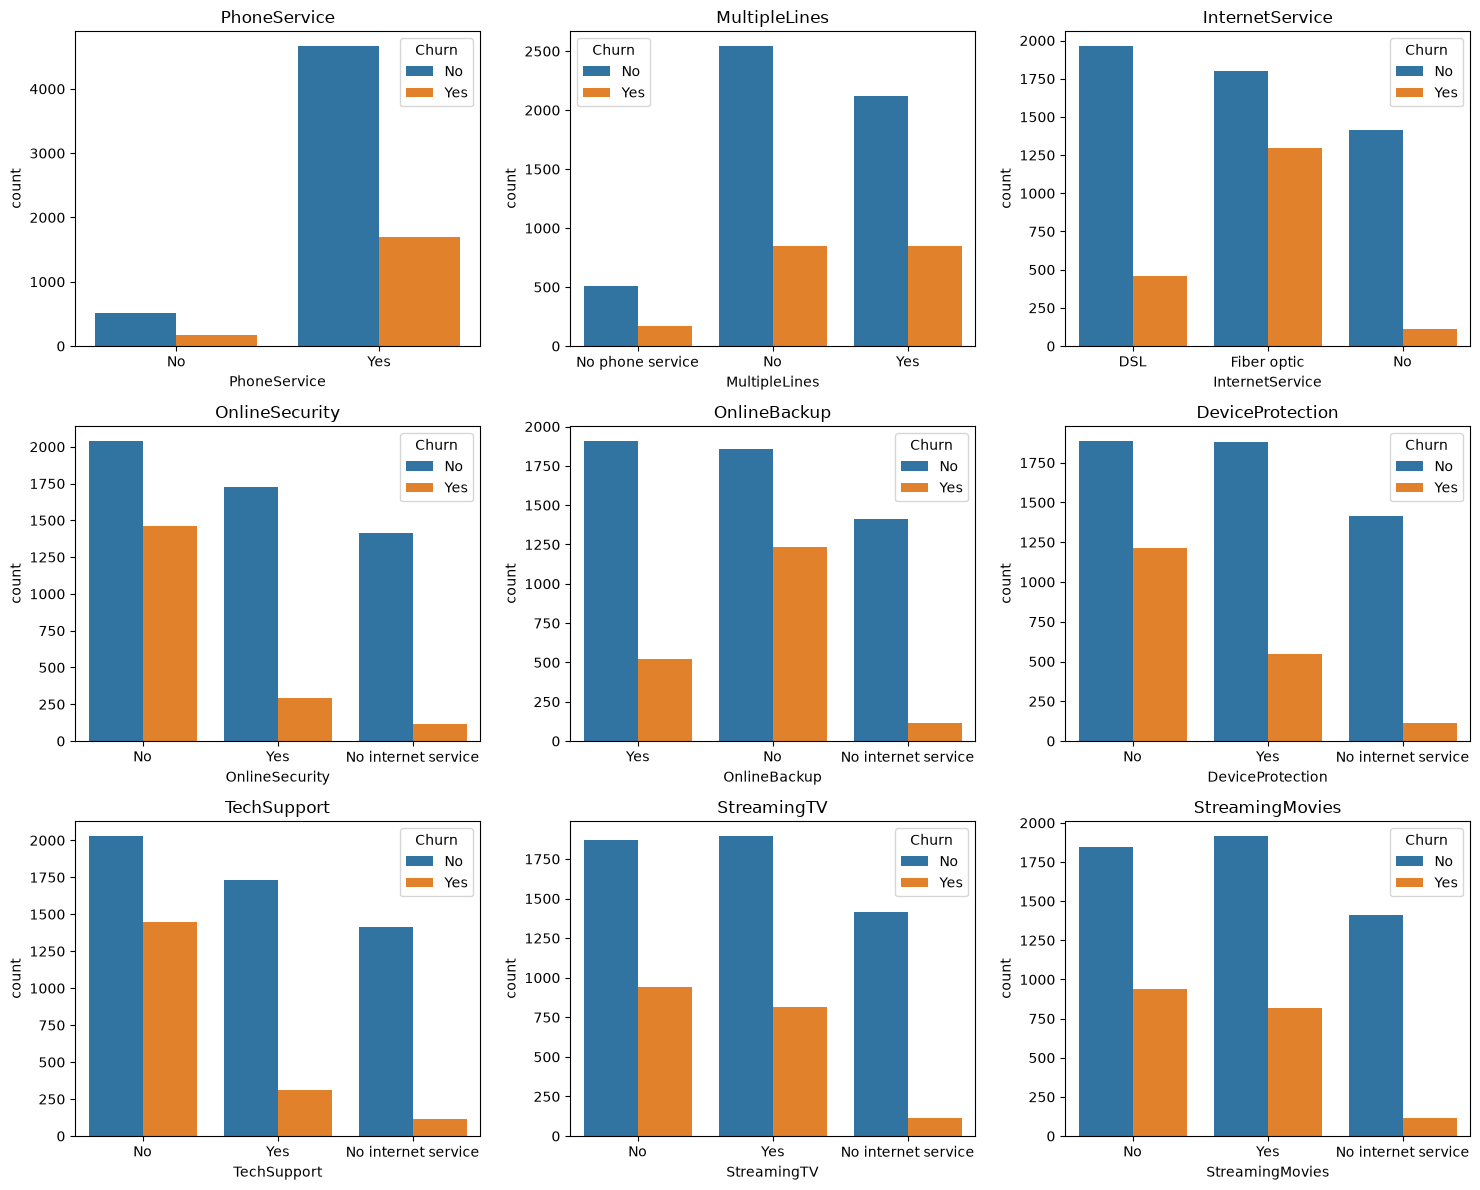

In [30]:
# List of all service-related columns to analyze churn based on services
columns = [
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies'
]
n_cols = 3
n_rows = (len(columns) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 12))
axes = axes.flatten() 

for i, col in enumerate(columns):
    sns.countplot(x=col, data=df, hue='Churn', ax=axes[i])
    axes[i].set_title(col)

for i in range(len(columns), len(axes)):
    fig.delaxes(axes[i])

plt.tight_layout()
plt.show()

In [31]:
#Making a Summary Table of Total Services vs Churn
total_services_summary = df.groupby(['TotalServices', 'Churn']).size().unstack(fill_value=0)
total_services_summary['Total'] = total_services_summary['No'] + total_services_summary['Yes']
total_services_summary['Churn_Rate_%'] = ((total_services_summary['Yes'] / total_services_summary['Total']) * 100).round(2)
print("Summary Table:")
print(total_services_summary)

Summary Table:
Churn            No  Yes  Total  Churn_Rate_%
TotalServices                                
1              1126  138   1264         10.92
2               593  266    859         30.97
3               466  380    846         44.92
4               613  352    965         36.48
5               633  289    922         31.34
6               676  232    908         25.55
7               524  152    676         22.49
8               346   49    395         12.41
9               197   11    208          5.29


C:\Users\ayush\AppData\Local\Temp\ipykernel_8404\3229967959.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


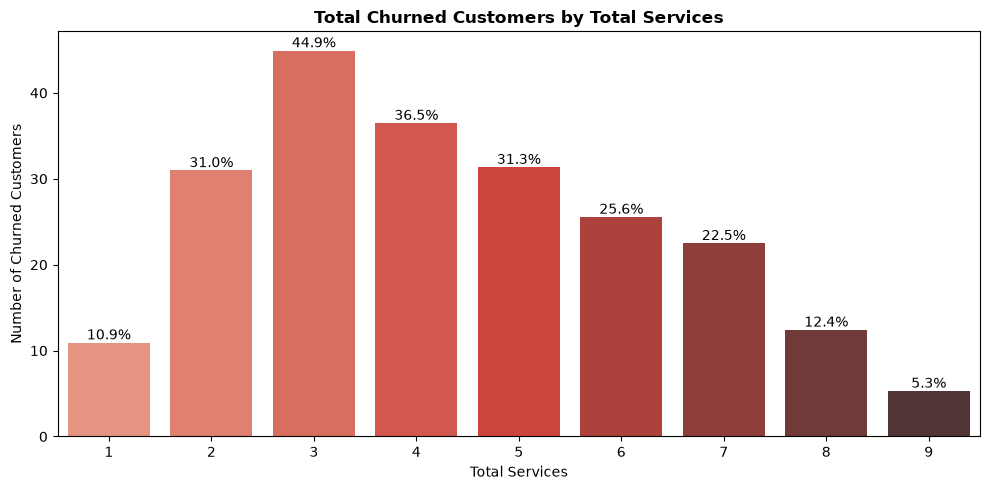

In [32]:
#Showcasing Churn counts based on Total Services via Bar Chart
plt.figure(figsize=(10, 5))
ax = sns.barplot(
    data=total_services_summary.reset_index(), 
    x='TotalServices', 
    y='Churn_Rate_%', 
    palette= 'Reds_d'
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge')

plt.title('Total Churned Customers by Total Services', fontsize=12, fontweight='bold')
plt.xlabel('Total Services', fontsize=10)
plt.ylabel('Number of Churned Customers', fontsize=10)
plt.tight_layout()
plt.show()

Users with 2-5 Total Services have higher churn rate

In [33]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk


In [34]:
#Summary Table for Risk Profile vs Churn
df['Churn_Numeric'] = (df['Churn'] == 'Yes').astype(int)
risk_summary = df.groupby('RiskProfile').agg(
    Customer_Count=('Churn', 'count'),
    Churned_Count=('Churn_Numeric', 'sum'),
    Churn_Rate_Pct=('Churn_Numeric', lambda x: round((x.sum() / x.count()) * 100, 2))
).reset_index()

print("Risk Profile Summary:")
print(risk_summary)

Risk Profile Summary:
   RiskProfile  Customer_Count  Churned_Count  Churn_Rate_Pct
0    High Risk            2132           1017           47.70
1     Low Risk            1998            185            9.26
2  Medium Risk            2913            667           22.90


C:\Users\ayush\AppData\Local\Temp\ipykernel_8404\1891432989.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(


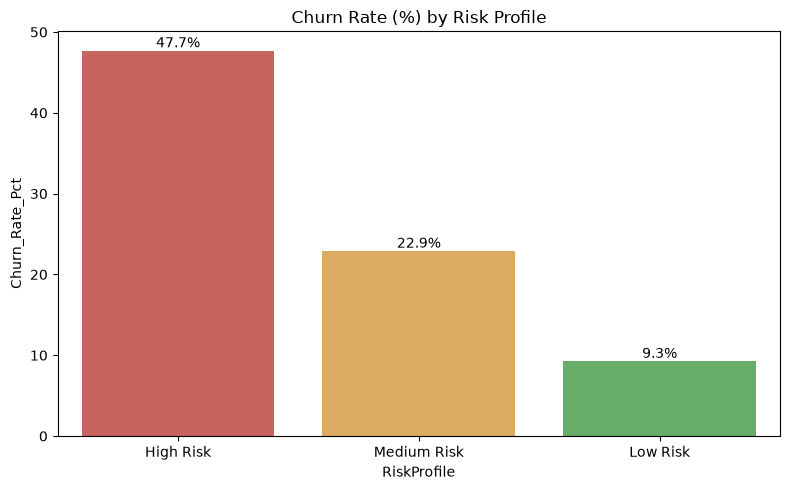

In [35]:
#Showcasing Churn Rate based on Risk Profile via Bar Chart
plt.figure(figsize=(8, 5))
ax = sns.barplot(
    data=risk_summary, 
    x='RiskProfile', 
    y='Churn_Rate_Pct', 
    order=['High Risk', 'Medium Risk', 'Low Risk'],
    palette=['#d9534f', '#f0ad4e', '#5cb85c']
)
for container in ax.containers:
    ax.bar_label(container, fmt='%.1f%%', label_type='edge')

plt.title('Churn Rate (%) by Risk Profile')
plt.tight_layout()
plt.show()

High Risk (%)- 47.7%
Medium Risk (%)- 22.9%
Low Risk (%)- 9.3%

In [36]:
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,TotalServices,RiskProfile,Churn_Numeric
0,7590-VHVEG,Female,No,Yes,No,1,No,No phone service,DSL,No,...,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,2,High Risk,0
1,5575-GNVDE,Male,No,No,No,34,Yes,No,DSL,Yes,...,No,One year,No,Mailed check,56.95,1889.50,No,4,Low Risk,0
2,3668-QPYBK,Male,No,No,No,2,Yes,No,DSL,Yes,...,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,4,High Risk,1
3,7795-CFOCW,Male,No,No,No,45,No,No phone service,DSL,Yes,...,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,4,Low Risk,0
4,9237-HQITU,Female,No,No,No,2,Yes,No,Fiber optic,No,...,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,2,High Risk,1


In [38]:
df = df.drop(columns=['Churn_Numeric'])

In [39]:
#Exporting Final Analysis
df.to_csv('analyzed_cleaned_churn.csv', index=False)